# Module 4: Applying First- and Higher-Order Markov Chains
## Forecasting LA Lakers Game Outcomes

**Course:** EAI 6000 Fundamentals of Artificial Intelligence  
**Instructor:** Professor Raj Saha  
**Date:** August 1, 2026

This notebook follows the supplied assignment prompt and extends the instructor's first-order example to Markov chains of orders 1, 2, 3, and 4.

### Generative AI Assistance Disclosure

OpenAI ChatGPT was used to help organize, comment, test, and debug portions of the higher-order Markov-chain code. The required functions contain an additional disclosure comment. I reviewed the logic, ran every cell, and verified the transition probabilities and simulation outputs.

In [ ]:
# Import the libraries used for data handling, simulation, and visualization.
from pathlib import Path
from itertools import product
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Show probabilities with four decimal places in pandas output.
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

# Use a fixed seed so that the saved notebook results are reproducible.
random.seed(6000)

## Supplied Helper Functions

The first function randomly selects one of two states from their probabilities. The second function extracts overlapping subsequences of length \(n\) from a sequence.

In [ ]:
def pick_state(var_a, prob_a, var_b, prob_b):
    """Randomly select one of two states using the supplied probabilities."""

    # Confirm that each probability is within the valid interval.
    if not (0 <= prob_a <= 1 and 0 <= prob_b <= 1):
        raise ValueError("Input probabilities must be between 0 and 1.")

    # Confirm that the probabilities form a valid two-state distribution.
    if not np.isclose(prob_a + prob_b, 1.0):
        raise ValueError("The two probabilities must add up to 1.")

    # Generate one random number from the interval [0, 1).
    random_value = random.random()

    # Select the first state when the number falls in its probability range.
    if random_value < prob_a:
        return var_a

    # Otherwise, select the second state.
    return var_b


def get_n_letter_sequences(sequence, n):
    """Return all overlapping subsequences of length n."""

    # Validate the requested subsequence length.
    if not isinstance(n, int) or n < 1:
        raise ValueError("n must be a positive integer.")

    # Use a sliding window to collect every overlapping subsequence.
    return [sequence[i:i + n] for i in range(len(sequence) - n + 1)]

In [ ]:
# Quick checks of the two supplied helper functions.
print("Example overlapping sequences:", get_n_letter_sequences("ABBBBABABA", 3))
print("Example random state:", pick_state("A", 0.3, "B", 0.7))

Example overlapping sequences: ['ABB', 'BBB', 'BBB', 'BBA', 'BAB', 'ABA', 'BAB', 'ABA']
Example random state: A


## Step 1: Read and Inspect the Dataset

In [ ]:
# Check the instructor's original filename and the filename of the downloaded copy.
candidate_files = [
    "LALakers_21-23.csv",
    "LALakers_21-23-1-1.csv",
    "data/LALakers_21-23.csv",
    "data/LALakers_21-23-1-1.csv",
]

# Select the first candidate that exists in the notebook environment.
data_path = next((Path(name) for name in candidate_files if Path(name).exists()), None)

# Stop with a clear message if the CSV has not been uploaded.
if data_path is None:
    raise FileNotFoundError(
        "Place LALakers_21-23.csv in the repository root (or data/ folder) and rerun this cell."
    )

# Read the game data into a pandas dataframe.
df_LAL = pd.read_csv(data_path)

# Remove the exported dataframe index column because it is not a game feature.
df_LAL = df_LAL.drop(columns=["Unnamed: 0"], errors="ignore")

# Convert the date column to pandas datetime values.
df_LAL["date"] = pd.to_datetime(df_LAL["date"])

# Display the first rows to verify that the file loaded correctly.
df_LAL.head()

,date,result,season
0,2021-10-19,L,21-22
1,2021-10-22,L,21-22
2,2021-10-24,W,21-22
3,2021-10-26,W,21-22
4,2021-10-27,L,21-22


In [ ]:
# Summarize the number of rows and known game results in each season.
dataset_summary = (
    df_LAL.groupby("season")
          .agg(
              Total_Rows=("result", "size"),
              Known_Results=("result", "count"),
              Missing_Results=("result", lambda values: values.isna().sum()),
          )
)

display(dataset_summary)

# Confirm that all known outcomes use the expected two states.
known_states = sorted(df_LAL["result"].dropna().unique().tolist())
print("Known outcome states:", known_states)

,Total_Rows,Known_Results,Missing_Results
season,,,
21-22,82,82,0
22-23,82,53,29


Known outcome states: ['L', 'W']


The two Markov states are **L** (loss) and **W** (win). The 2021-22 season contains 82 known results. The 2022-23 season contains 53 known results and 29 missing results, representing the games that remained when the assignment dataset was created.

## Steps 2-3: Reproduce the Supplied First-Order Example

In [ ]:
# Use the first 40 games of the 2021-22 season as the training sequence,
# matching the split in the supplied notebook.
season_2122 = df_LAL.loc[df_LAL["season"] == "21-22", "result"].dropna()

# Join the first half into one training string.
seq_train = "".join(season_2122.iloc[:40].tolist())

# Keep the remaining known outcomes as the test array.
seq_test = season_2122.iloc[40:].to_numpy()

print("Training games:", len(seq_train))
print("Test games:", len(seq_test))
print("Training sequence:", seq_train)
print("Test sequence:", "".join(seq_test))

Training games: 40
Test games: 42
Training sequence: LLWWLWWWLLWWLWLLLWLWLWWLWLWWWLLLLLWLWWWW
Test sequence: LLLWLWLWLLLWLWLLLWLLLLWLLWLLLWLWLLLLLLLLWW


In [ ]:
# Extract all one-state contexts from the training sequence.
seq_1_list = np.array(get_n_letter_sequences(seq_train, 1))

# Sort the unique one-state contexts so the matrix columns are L and W.
unique_seq_1_list = np.sort(np.unique(seq_1_list))

# Extract every two-state sequence because each one contains a context
# followed by its next outcome.
seq_2_list = np.array(get_n_letter_sequences(seq_train, 2))

# Create a two-row matrix: row 0 is next-state L and row 1 is next-state W.
arr_tr_mat_order_1 = np.zeros((2, len(unique_seq_1_list)))

# Compute the empirical next-state probabilities for each context.
for column_index, context in enumerate(unique_seq_1_list):

    # Count how often L follows the current context.
    count_next_L = np.sum(seq_2_list == context + "L")

    # Count how often W follows the current context.
    count_next_W = np.sum(seq_2_list == context + "W")

    # Count all observed transitions from this context.
    total_transitions = count_next_L + count_next_W

    # Convert the counts to transition probabilities.
    arr_tr_mat_order_1[0, column_index] = count_next_L / total_transitions
    arr_tr_mat_order_1[1, column_index] = count_next_W / total_transitions

# Display the transition matrix with meaningful labels.
df_transition_order_1 = pd.DataFrame(
    arr_tr_mat_order_1,
    index=["Next_L", "Next_W"],
    columns=unique_seq_1_list,
)

df_transition_order_1

,L,W
Next_L,0.4211,0.5000
Next_W,0.5789,0.5000


In [ ]:
# Generate one complete first-order forecast of the test period.
predictions_order_1 = []

# The final training result is the first known context.
current_context = seq_train[-1]

# Generate the same number of predictions as known test outcomes.
for _ in range(len(seq_test)):

    # Select the transition-matrix column matching the current context.
    context_vector = np.where(unique_seq_1_list == current_context, 1, 0)

    # Matrix-vector multiplication gives P(next=L) and P(next=W).
    next_probabilities = arr_tr_mat_order_1 @ context_vector

    # Randomly select the next outcome from those probabilities.
    next_state = pick_state(
        "L",
        float(next_probabilities[0]),
        "W",
        float(next_probabilities[1]),
    )

    # Save the simulated outcome.
    predictions_order_1.append(next_state)

    # In a first-order model, the newly predicted outcome becomes the context.
    current_context = next_state

# Compare the simulated sequence with the known test sequence.
df_validation_order_1 = pd.DataFrame(
    {"Actual": seq_test, "Predicted": predictions_order_1}
)

# Calculate the fraction of correctly predicted games.
single_run_accuracy = (
    df_validation_order_1["Actual"] == df_validation_order_1["Predicted"]
).mean()

print("First-order forecast:", "".join(predictions_order_1))
print(f"Single-run accuracy: {single_run_accuracy:.4f} ({single_run_accuracy:.2%})")
display(df_validation_order_1.head(10))

First-order forecast: LLWLWWWLWLWWLWWLLWLWLWWLLLLWWWWLLWLWWWLLLW
Single-run accuracy: 0.5238 (52.38%)


,Actual,Predicted
0,L,L
1,L,L
2,L,W
3,W,L
4,L,W
5,W,W
6,L,W
7,W,L
8,L,W
9,L,L


## Step 4: Higher-Order Transition-Matrix Function

In [ ]:
def get_transition_matrix_order_n(training_sequence, order):
    """Return a two-row transition matrix for an order-n Markov chain.

    Rows represent the next outcome, L or W. Columns represent every
    possible history of length n. Each column sums to 1.

    Generative AI disclosure: OpenAI ChatGPT assisted with organizing,
    commenting, and testing this function. I reviewed every line.
    """

    # Confirm that the training sequence is a string.
    if not isinstance(training_sequence, str):
        raise TypeError("training_sequence must be a string.")

    # Confirm that the order is a positive integer.
    if not isinstance(order, int) or order < 1:
        raise ValueError("order must be a positive integer.")

    # Confirm that enough observations exist to form an order-n transition.
    if len(training_sequence) <= order:
        raise ValueError("training_sequence must contain more values than the order.")

    # Confirm that the two-state sequence contains only L and W.
    if any(state not in {"L", "W"} for state in training_sequence):
        raise ValueError("training_sequence may contain only 'L' and 'W'.")

    # Generate every possible length-n context in a consistent sorted order.
    context_states = [
        "".join(state_tuple)
        for state_tuple in product(["L", "W"], repeat=order)
    ]

    # Extract every observed sequence containing n context states plus one next state.
    transition_sequences = get_n_letter_sequences(training_sequence, order + 1)

    # Create an empty labeled matrix with next states as rows and contexts as columns.
    transition_matrix = pd.DataFrame(
        index=["L", "W"],
        columns=context_states,
        dtype=float,
    )

    # Calculate the transition probabilities for each possible context.
    for context in context_states:

        # Count the observed transitions from this context to a loss.
        count_next_L = transition_sequences.count(context + "L")

        # Count the observed transitions from this context to a win.
        count_next_W = transition_sequences.count(context + "W")

        # Count every observed next state following the context.
        total_outgoing = count_next_L + count_next_W

        # Use a neutral distribution when a context has no observed outgoing transition.
        # This can occur when a context appears only at the end of the training sequence.
        if total_outgoing == 0:
            probability_L = 0.5
            probability_W = 0.5

        # Otherwise, use the empirical transition frequencies.
        else:
            probability_L = count_next_L / total_outgoing
            probability_W = count_next_W / total_outgoing

        # Store P(next=L | context) in the first row.
        transition_matrix.loc["L", context] = probability_L

        # Store P(next=W | context) in the second row.
        transition_matrix.loc["W", context] = probability_W

    # Return the completed transition matrix.
    return transition_matrix

In [ ]:
# Build and validate transition matrices for all required orders.
orders = [1, 2, 3, 4]
transition_matrices = {}
matrix_checks = []

for order in orders:
    # Generate the transition matrix for this order.
    matrix = get_transition_matrix_order_n(seq_train, order)

    # Save the matrix for later simulations.
    transition_matrices[order] = matrix

    # Check its dimensions and whether every column sums to one.
    matrix_checks.append({
        "Order": order,
        "Rows": matrix.shape[0],
        "Columns": matrix.shape[1],
        "Minimum_Column_Sum": matrix.sum(axis=0).min(),
        "Maximum_Column_Sum": matrix.sum(axis=0).max(),
    })

display(pd.DataFrame(matrix_checks))

print("\nOrder-1 transition matrix:")
display(transition_matrices[1].round(3))

print("\nOrder-2 transition matrix:")
display(transition_matrices[2].round(3))

print("\nOrder-4 transition matrix:")
display(transition_matrices[4].round(3))

,Order,Rows,Columns,Minimum_Column_Sum,Maximum_Column_Sum
0,1,2,2,1.0000,1.0000
1,2,2,4,1.0000,1.0000
2,3,2,8,1.0000,1.0000
3,4,2,16,1.0000,1.0000



Order-1 transition matrix:


,L,W
L,0.4210,0.5000
W,0.5790,0.5000



Order-2 transition matrix:


,LL,LW,WL,WW
L,0.5000,0.4550,0.3000,0.5560
W,0.5000,0.5450,0.7000,0.4440



Order-4 transition matrix:


,LLLL,LLLW,LLWL,LLWW,LWLL,LWLW,LWWL,LWWW,WLLL,WLLW,WLWL,WLWW,WWLL,WWLW,WWWL,WWWW
L,0.5000,1.0000,0.0000,1.0000,1.0000,0.2500,0.0000,0.6670,0.5000,0.0000,0.3330,0.2500,0.5000,0.6670,1.0000,0.5000
W,0.5000,0.0000,1.0000,0.0000,0.0000,0.7500,1.0000,0.3330,0.5000,1.0000,0.6670,0.7500,0.5000,0.3330,0.0000,0.5000


The number of columns doubles with each increase in order because a two-state system has \(2^n\) possible histories of length \(n\). Every matrix has two rows, and each column sums to 1 because the next game must be either a loss or a win.

## Step 5: Prediction-Accuracy Function

In [ ]:
def get_prediction_accuracy(
    training_sequence,
    test_sequence,
    order,
    transition_matrix,
):
    """Simulate one test-length forecast and return its accuracy.

    Generative AI disclosure: OpenAI ChatGPT assisted with organizing,
    commenting, and testing this function. I reviewed every line.
    """

    # Confirm that the training sequence is a string.
    if not isinstance(training_sequence, str):
        raise TypeError("training_sequence must be a string.")

    # Convert the test values to a NumPy array for vectorized comparison.
    test_array = np.asarray(test_sequence)

    # Confirm that the test outcomes use only the two valid states.
    if not set(test_array).issubset({"L", "W"}):
        raise ValueError("test_sequence may contain only 'L' and 'W'.")

    # Confirm that the order is valid for the training sequence.
    if not isinstance(order, int) or order < 1 or order >= len(training_sequence):
        raise ValueError("order must be positive and smaller than the training sequence.")

    # Use the final n training outcomes as the starting context.
    current_context = training_sequence[-order:]

    # Create a list that will store the simulated outcomes.
    predictions = []

    # Generate one forecast for every known outcome in the test sequence.
    for _ in range(len(test_array)):

        # Confirm that the current context has a column in the transition matrix.
        if current_context not in transition_matrix.columns:
            raise KeyError(f"Context {current_context!r} is missing from the matrix.")

        # Read P(next=L) and P(next=W) from the matching matrix column.
        next_probabilities = transition_matrix.loc[
            ["L", "W"], current_context
        ].to_numpy(dtype=float)

        # Randomly select the next state from the two probabilities.
        next_state = pick_state(
            "L",
            float(next_probabilities[0]),
            "W",
            float(next_probabilities[1]),
        )

        # Save the simulated state.
        predictions.append(next_state)

        # Append the prediction and retain only the latest n states.
        current_context = (current_context + next_state)[-order:]

    # Convert the predictions to an array for comparison.
    prediction_array = np.asarray(predictions)

    # Calculate the proportion of positions that match the known outcomes.
    accuracy = np.mean(prediction_array == test_array)

    # Return the net accuracy as a floating-point value.
    return float(accuracy)

In [ ]:
# Test the function once at every required order.
random.seed(6000)

single_run_results = []

for order in orders:
    # Run one complete simulated forecast for this order.
    accuracy_value = get_prediction_accuracy(
        seq_train,
        seq_test,
        order,
        transition_matrices[order],
    )

    # Save the result in an organized table.
    single_run_results.append({
        "Order": order,
        "Single_Run_Accuracy": accuracy_value,
    })

display(pd.DataFrame(single_run_results))

,Order,Single_Run_Accuracy
0,1,0.5476
1,2,0.5476
2,3,0.5000
3,4,0.5714


## Step 6: Monte Carlo Simulations for Orders 1-4

In [ ]:
# Use 1,000 simulations per order, which exceeds the required 100+ runs.
number_of_simulations = 1000

# Reset the seed so this experiment is reproducible.
random.seed(6000)

# Store one row for every order-simulation combination.
simulation_records = []

for order in orders:

    # Use the already validated transition matrix for this order.
    matrix = transition_matrices[order]

    for simulation_number in range(1, number_of_simulations + 1):

        # Simulate a full test-period forecast and calculate its accuracy.
        accuracy_value = get_prediction_accuracy(
            seq_train,
            seq_test,
            order,
            matrix,
        )

        # Save the order, simulation number, and resulting accuracy.
        simulation_records.append({
            "Order": order,
            "Simulation": simulation_number,
            "Accuracy": accuracy_value,
        })

# Convert all stored simulation results into a dataframe.
df_simulations = pd.DataFrame(simulation_records)

# Display the first rows to verify the required structure.
df_simulations.head()

,Order,Simulation,Accuracy
0,1,1,0.5476
1,1,2,0.5000
2,1,3,0.5476
3,1,4,0.5000
4,1,5,0.4048


In [ ]:
# Summarize the center and spread of the accuracy distribution for each order.
accuracy_summary = (
    df_simulations.groupby("Order")["Accuracy"]
                  .agg(
                      Mean="mean",
                      Median="median",
                      Standard_Deviation="std",
                      Minimum="min",
                      Maximum="max",
                  )
)

accuracy_summary

,Mean,Median,Standard_Deviation,Minimum,Maximum
Order,,,,,
1,0.4871,0.5000,0.0756,0.2381,0.7143
2,0.4785,0.4762,0.0807,0.2381,0.7619
3,0.4930,0.5000,0.0767,0.2381,0.7381
4,0.5059,0.5000,0.0847,0.2619,0.7381


## Step 7: Boxplot and Interpretation

/tmp/ipykernel_1095/4152577830.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


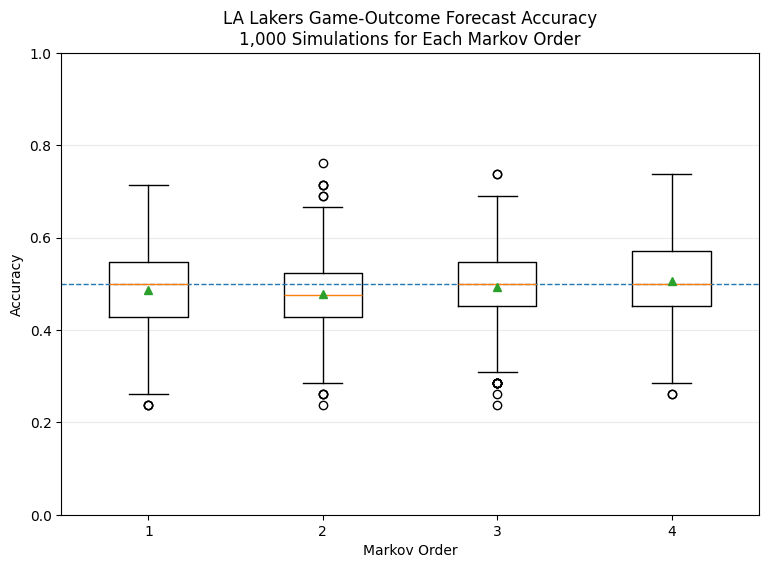

In [ ]:
# Prepare one accuracy array for each order.
accuracy_by_order = [
    df_simulations.loc[df_simulations["Order"] == order, "Accuracy"].to_numpy()
    for order in orders
]

# Create one boxplot so the distributions can be compared directly.
fig, ax = plt.subplots(figsize=(9, 6))

# Show the median as the center line and the mean as a triangle.
ax.boxplot(
    accuracy_by_order,
    labels=orders,
    showmeans=True,
)

# Add a 50% reference line for a simple two-state comparison.
ax.axhline(0.5, linestyle="--", linewidth=1)

# Label the chart clearly.
ax.set_title(
    "LA Lakers Game-Outcome Forecast Accuracy\n"
    "1,000 Simulations for Each Markov Order"
)
ax.set_xlabel("Markov Order")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)

plt.show()

### Observation

The accuracy does **not** increase consistently as the Markov order increases. In the 1,000 saved simulations, the mean accuracy is approximately 48.71% for order 1, 47.85% for order 2, 49.30% for order 3, and 50.59% for order 4. The median is 50.00% for orders 1, 3, and 4, while order 2 has a slightly lower median of 47.62%.

Order 4 has the highest mean in this experiment, but the improvement is small and its distribution is somewhat wider. A higher order uses more recent outcomes as context, but it also divides a short training sequence among many more possible histories. As a result, each transition probability is estimated from fewer observations. This data-sparsity tradeoff explains why increasing the order does not guarantee better accuracy.

In [ ]:
# Compare the Markov simulations with a simple majority-class baseline.
test_loss_rate = np.mean(seq_test == "L")
test_win_rate = np.mean(seq_test == "W")
majority_baseline = max(test_loss_rate, test_win_rate)

print(f"Test loss rate: {test_loss_rate:.2%}")
print(f"Test win rate: {test_win_rate:.2%}")
print(f"Majority-class baseline accuracy: {majority_baseline:.2%}")

Test loss rate: 71.43%
Test win rate: 28.57%
Majority-class baseline accuracy: 71.43%


The test period contains substantially more losses than wins, so always predicting the majority outcome would score 71.43%. That baseline is higher than the average Markov simulation accuracy. This does not mean the code is incorrect. It shows that the short first-half sequence did not provide stable transition patterns that matched the unusually loss-heavy second half.

## Step 8: Alternative Training-Data Choices

Yes, other training-data choices could produce better and more reliable results.

First, a larger training sample could reduce the instability of higher-order transition probabilities. For example, the full previous season could be combined with the completed games from the current season. However, older games should not automatically receive equal weight because roster, coaching, injuries, and team performance can change.

Second, a rolling or expanding training window would better reflect how a real forecast is made. After each completed game, the training sequence could be updated and the next game predicted. Several window lengths could then be compared using time-ordered validation rather than choosing a model from one fixed split.

For forecasting the remaining 2022-23 games, the 53 completed games from that same season are likely more representative than only the first 40 games of 2021-22. Additional states such as home versus away, opponent strength, and player availability might also improve prediction, although that would extend the model beyond the assignment's two-state Markov chain.

## Step 9 (Optional): Forecast the Remaining 29 Games

In [ ]:
def forecast_game_sequence(
    training_sequence,
    number_of_games,
    order,
    transition_matrix,
):
    """Generate a simulated sequence of future L/W game outcomes."""

    # Begin with the most recent n known outcomes.
    current_context = training_sequence[-order:]

    # Create a list for the future outcomes.
    forecast = []

    # Generate the requested number of future games.
    for _ in range(number_of_games):

        # Read the two next-state probabilities from the matrix.
        next_probabilities = transition_matrix.loc[
            ["L", "W"], current_context
        ].to_numpy(dtype=float)

        # Randomly select the next game result.
        next_state = pick_state(
            "L",
            float(next_probabilities[0]),
            "W",
            float(next_probabilities[1]),
        )

        # Save the result.
        forecast.append(next_state)

        # Update the history for the next forecast.
        current_context = (current_context + next_state)[-order:]

    # Return the simulated outcomes as one sequence string.
    return "".join(forecast)

In [ ]:
# Select the order with the highest mean validation accuracy.
best_order = int(accuracy_summary["Mean"].idxmax())

# Use every known 2022-23 result as the current-season training sequence.
current_season_known = "".join(
    df_LAL.loc[
        (df_LAL["season"] == "22-23") & df_LAL["result"].notna(),
        "result",
    ].tolist()
)

# Count the games without known results in the supplied dataset.
remaining_games = int(
    df_LAL.loc[
        (df_LAL["season"] == "22-23") & df_LAL["result"].isna()
    ].shape[0]
)

# Build a current-season transition matrix at the selected order.
current_season_matrix = get_transition_matrix_order_n(
    current_season_known,
    best_order,
)

# Generate one reproducible illustrative forecast sequence.
random.seed(6000)
sample_forecast = forecast_game_sequence(
    current_season_known,
    remaining_games,
    best_order,
    current_season_matrix,
)

print("Selected order:", best_order)
print("Remaining games:", remaining_games)
print("Illustrative forecast:", sample_forecast)
print("Forecast wins:", sample_forecast.count("W"))
print("Forecast losses:", sample_forecast.count("L"))

Selected order: 4
Remaining games: 29
Illustrative forecast: LLLWLWWWLWWWWLWWLLLLWLWWLLLLW
Forecast wins: 14
Forecast losses: 15


In [ ]:
# Run many future-season simulations to avoid relying on only one random path.
random.seed(6000)
future_win_counts = []

for _ in range(5000):

    # Generate one possible 29-game future.
    simulated_future = forecast_game_sequence(
        current_season_known,
        remaining_games,
        best_order,
        current_season_matrix,
    )

    # Store the number of wins in that possible future.
    future_win_counts.append(simulated_future.count("W"))

# Summarize the distribution of forecast wins.
future_forecast_summary = pd.Series(future_win_counts).agg(
    ["mean", "median", "min", "max"]
)

print("Future-win simulation summary:")
display(future_forecast_summary.to_frame("Forecast_Wins"))

print(
    "Central 95% interval:",
    np.quantile(future_win_counts, [0.025, 0.975]),
)

Future-win simulation summary:


,Forecast_Wins
mean,14.1518
median,14.0000
min,7.0000
max,23.0000


Central 95% interval: [10. 18.]


### Optional Forecast Interpretation

Order 4 has the highest mean validation accuracy in the saved Monte Carlo experiment, so it is used for the optional forecast. The illustrative 29-game path predicts 14 wins and 15 losses. Across 5,000 simulated futures, the model predicts an average of about 14.15 wins, with a central 95% interval of approximately 10 to 18 wins.

This is a probability-based classroom exercise rather than a dependable sports-betting model. The forecast uses only previous win/loss sequences and ignores opponents, home-court advantage, trades, injuries, and other information that materially affects basketball outcomes.

## Final Rubric Check

- The CSV is read and inspected in pandas.
- The supplied first-order process is reproduced and explained.
- `get_transition_matrix_order_n()` works for orders 1-4 and every line is commented.
- `get_prediction_accuracy()` performs a full recursive forecast and every line is commented.
- 1,000 simulations are run for each required order.
- Accuracy values and order numbers are stored in a dataframe.
- A labeled boxplot displays means, medians, quartiles, and ranges.
- Questions 7 and 8 are answered clearly and concisely.
- The optional 29-game forecast is completed.
- Generative AI assistance is disclosed as required.